In [1]:
import pandas as pd, numpy as np
from sklearn.model_selection import GroupShuffleSplit

sim = pd.read_csv("data/simulated_population.csv")
sim["dip_key"] = sim.apply(lambda r: "/".join(sorted([r["allele1"], r["allele2"]])), axis=1)

alleles = sorted(set(sim["allele1"]) | set(sim["allele2"]))
X = pd.DataFrame({a: (sim["allele1"] == a).astype(int) + (sim["allele2"] == a).astype(int)
                  for a in alleles})
y = sim["phenotype"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=sim["dip_key"]))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("Features:", X.shape[1], "| Train:", len(train_idx), "| Test:", len(test_idx))
print("Diplotype overlap:", len(set(sim.iloc[train_idx]["dip_key"]) & set(sim.iloc[test_idx]["dip_key"])))


Features: 71 | Train: 40542 | Test: 4458
Diplotype overlap: 0


In [2]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print("Test-set diplotypes per class:")
print(sim.iloc[test_idx].groupby("phenotype")["dip_key"].nunique())

rf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                            random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
pred = rf.predict(X_test)

print()
print("Accuracy:", round(accuracy_score(y_test, pred), 4))
print(classification_report(y_test, pred, digits=3))

Test-set diplotypes per class:
phenotype
CYP2D6 Intermediate Metabolizer    63
CYP2D6 Normal Metabolizer          35
CYP2D6 Poor Metabolizer            16
CYP2D6 Ultrarapid Metabolizer       7
Name: dip_key, dtype: int64

Accuracy: 0.5159
                                 precision    recall  f1-score   support

CYP2D6 Intermediate Metabolizer      0.489     0.760     0.595      1640
      CYP2D6 Normal Metabolizer      0.665     0.271     0.385      2410
        CYP2D6 Poor Metabolizer      0.462     0.917     0.615        60
  CYP2D6 Ultrarapid Metabolizer      0.429     0.991     0.598       348

                       accuracy                          0.516      4458
                      macro avg      0.511     0.735     0.548      4458
                   weighted avg      0.579     0.516     0.482      4458



              Poor  Intermediate  Normal  Ultrarapid
Poor            55             5       0           0
Intermediate    64          1247     329           0
Normal           0          1297     653         460
Ultrarapid       0             3       0         345


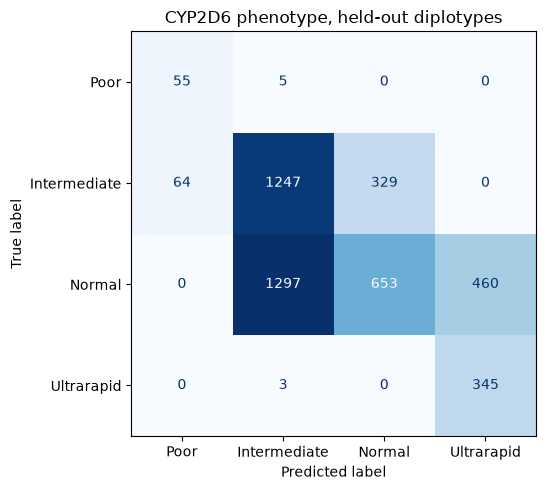

In [3]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

labels = ["CYP2D6 Poor Metabolizer", "CYP2D6 Intermediate Metabolizer",
          "CYP2D6 Normal Metabolizer", "CYP2D6 Ultrarapid Metabolizer"]
short = ["Poor", "Intermediate", "Normal", "Ultrarapid"]
cm = confusion_matrix(y_test, pred, labels=labels)
print(pd.DataFrame(cm, index=short, columns=short))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=short).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("CYP2D6 phenotype, held-out diplotypes")
plt.tight_layout()
plt.savefig("cyp2d6_confusion_matrix.png", dpi=300)
plt.show()

In [4]:
fn = pd.read_excel("data/CYP2D6_allele_functionality_reference.xlsx",
                   sheet_name="Allele Function", header=1).iloc[:, [0, 1]]
fn.columns = ["allele", "activity"]
fn["allele"] = fn["allele"].astype(str).str.strip()
fn["act"] = pd.to_numeric(fn["activity"], errors="coerce")

fr = pd.read_excel("data/CYP2D6_frequency_table.xlsx",
                   sheet_name="Allele frequency", header=1)
fr["allele"] = fr.iloc[:, 0].astype(str).str.strip()

used = set(fr["allele"]) & set(fn.loc[fn["act"].notna(), "allele"])
print(len(used), "alleles in the simulation list")
print("Not drawn in the simulation:", sorted(used - set(alleles)))

C:\Users\lenovo\anaconda3\envs\cyp2d6\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


72 alleles in the simulation list
Not drawn in the simulation: ['*38']


C:\Users\lenovo\anaconda3\envs\cyp2d6\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [5]:
test = sim.iloc[test_idx].copy()
test["pred"] = pred
test["correct"] = test["pred"] == test["phenotype"]

top = (test.groupby(["dip_key", "phenotype"])
           .agg(people=("correct", "size"), accuracy=("correct", "mean"))
           .sort_values("people", ascending=False).head(12))
print(top.round(2))
print()
print("Share of test people in the 12 biggest diplotypes:",
      round(top["people"].sum() / len(test), 2))
print()
for a in ["*1", "*2", "*41"]:
    print(a, "| count values in train:", sorted(X_train[a].unique()),
          "| in test:", sorted(X_test[a].unique()))
print()
print("Frequency of *38 in the CPIC table (max over populations):")
print(fr.loc[fr["allele"] == "*38", fr.columns[1:10]].max(axis=1))

                                          people  accuracy
dip_key  phenotype                                        
*10/*2   CYP2D6 Normal Metabolizer          1209       0.0
*1/*35   CYP2D6 Normal Metabolizer           452       1.0
*17/*17  CYP2D6 Intermediate Metabolizer     381       1.0
*1/*2x2  CYP2D6 Ultrarapid Metabolizer       295       1.0
*17/*5   CYP2D6 Intermediate Metabolizer     265       1.0
*10/*17  CYP2D6 Intermediate Metabolizer     223       1.0
*1x2/*41 CYP2D6 Normal Metabolizer           138       0.0
*10/*1x2 CYP2D6 Normal Metabolizer           131       0.0
*29/*41  CYP2D6 Intermediate Metabolizer     114       1.0
*2/*4x2  CYP2D6 Intermediate Metabolizer     106       0.0
*2x2/*41 CYP2D6 Normal Metabolizer            96       0.0
*1/*34   CYP2D6 Normal Metabolizer            90       1.0

Share of test people in the 12 biggest diplotypes: 0.79

*1 | count values in train: [np.int64(0), np.int64(1), np.int64(2)] | in test: [np.int64(0), np.int64(1)]
*2 | count

In [6]:
d = (test.groupby("dip_key")
         .agg(people=("correct", "size"), score=("score", "first"),
              truth=("phenotype", "first"), acc=("correct", "mean"))
         .reset_index())
d["truth"] = d["truth"].str.replace("CYP2D6 ", "").str.replace(" Metabolizer", "")

print("Diplotypes:", len(d), "| fully correct:", (d["acc"] == 1).sum(),
      "| fully wrong:", (d["acc"] == 0).sum())
print("Diplotype-level accuracy:", round((d["acc"] > 0.5).mean(), 3))
print()
print("Per class, share of diplotypes correct:")
print(d.groupby("truth")["acc"].agg(["mean", "count"]).round(2))
print()
print("Wrong diplotypes (score, truth):")
print(d[d["acc"] < 0.5].sort_values("people", ascending=False)
        [["dip_key", "score", "truth", "people"]].head(25).to_string(index=False))
print()
print("Scores of wrong diplotypes:", sorted(d[d["acc"] < 0.5]["score"].unique()))

Diplotypes: 121 | fully correct: 67 | fully wrong: 54
Diplotype-level accuracy: 0.554

Per class, share of diplotypes correct:
              mean  count
truth                    
Intermediate  0.57     63
Normal        0.34     35
Poor          0.81     16
Ultrarapid    0.86      7

Wrong diplotypes (score, truth):
  dip_key  score        truth  people
   *10/*2   1.25       Normal    1209
 *1x2/*41   2.25       Normal     138
 *10/*1x2   2.25       Normal     131
  *2/*4x2   1.00 Intermediate     106
 *2x2/*41   2.25       Normal      96
  *1x2/*5   2.00       Normal      68
    *2/*7   1.00 Intermediate      44
   *1/*69   1.00 Intermediate      41
   *2/*40   1.00 Intermediate      37
  *41/*45   1.25       Normal      34
   *2/*36   1.00 Intermediate      25
 *45/*4x2   1.00 Intermediate      23
   *12/*2   1.00 Intermediate      20
  *34/*41   1.25       Normal      15
  *10/*27   1.25       Normal      13
  *41/*46   1.25       Normal      12
  *1/*100   1.00 Intermediate      11

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score

classes = ["CYP2D6 Poor Metabolizer", "CYP2D6 Intermediate Metabolizer",
           "CYP2D6 Normal Metabolizer", "CYP2D6 Ultrarapid Metabolizer"]
rows = []
for seed in range(5):
    g = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)
    tr, te = next(g.split(X, y, groups=sim["dip_key"]))
    for name, model in [
        ("RandomForest", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                random_state=42, n_jobs=-1)),
        ("LogisticRegression", LogisticRegression(C=10, class_weight="balanced", max_iter=5000)),
    ]:
        model.fit(X.iloc[tr], y.iloc[tr])
        p = model.predict(X.iloc[te])
        t = sim.iloc[te].assign(ok=(p == y.iloc[te].to_numpy()))
        dip_acc = t.groupby("dip_key")["ok"].mean().gt(0.5).mean()
        rec = recall_score(y.iloc[te], p, labels=classes, average=None, zero_division=0)
        rows.append([seed, name, round((p == y.iloc[te].to_numpy()).mean(), 3),
                     round(dip_acc, 3), *rec.round(3)])

res = pd.DataFrame(rows, columns=["seed", "model", "person_acc", "diplotype_acc",
                                  "recall_Poor", "recall_Inter", "recall_Normal", "recall_Ultra"])
print(res.to_string(index=False))
print()
print(res.groupby("model")[["person_acc", "diplotype_acc", "recall_Poor", "recall_Inter",
                            "recall_Normal", "recall_Ultra"]].agg(["mean", "std"]).round(3).T)
res.to_csv("data/model_comparison_5_splits.csv", index=False)

 seed              model  person_acc  diplotype_acc  recall_Poor  recall_Inter  recall_Normal  recall_Ultra
    0       RandomForest       0.344          0.661        0.899         0.982          0.096         0.683
    0 LogisticRegression       0.961          0.860        1.000         0.972          0.958         0.634
    1       RandomForest       0.786          0.570        0.978         0.681          0.826         0.902
    1 LogisticRegression       0.992          0.802        0.998         0.989          0.995         0.829
    2       RandomForest       0.352          0.587        0.800         0.817          0.146         0.008
    2 LogisticRegression       0.993          0.826        0.875         0.986          0.997         0.997
    3       RandomForest       0.372          0.612        0.941         0.750          0.140         0.811
    3 LogisticRegression       0.990          0.901        0.985         0.982          0.997         0.905
    4       RandomForest    

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

lr = LogisticRegression(C=10, class_weight="balanced", max_iter=5000).fit(X_train, y_train)
p = lr.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, p), 4))
print(classification_report(y_test, p, digits=3))

test = sim.iloc[test_idx].copy()
test["ok"] = (p == test["phenotype"].to_numpy())
train_counts = X_train.sum()
dd = (test.groupby("dip_key")
          .agg(people=("ok", "size"), acc=("ok", "mean"),
               score=("score", "first"), truth=("phenotype", "first")).reset_index())
dd["rarest_allele_train_rows"] = dd["dip_key"].apply(
    lambda d: min(train_counts[a] for a in d.split("/")))

print("Diplotype-level accuracy:", round((dd["acc"] > 0.5).mean(), 3))
print()
print("Wrong diplotypes:")
print(dd[dd["acc"] <= 0.5].sort_values("people", ascending=False)
        [["dip_key", "score", "truth", "people", "rarest_allele_train_rows"]]
        .head(20).to_string(index=False))
print()
print("Median training rows of the rarest allele, correct vs wrong diplotypes:")
print(dd.groupby(dd["acc"] > 0.5)["rarest_allele_train_rows"].median())

Accuracy: 0.9886
                                 precision    recall  f1-score   support

CYP2D6 Intermediate Metabolizer      0.998     0.987     0.993      1640
      CYP2D6 Normal Metabolizer      0.993     0.988     0.990      2410
        CYP2D6 Poor Metabolizer      0.937     0.983     0.959        60
  CYP2D6 Ultrarapid Metabolizer      0.928     1.000     0.963       348

                       accuracy                          0.989      4458
                      macro avg      0.964     0.990     0.976      4458
                   weighted avg      0.989     0.989     0.989      4458

Diplotype-level accuracy: 0.843

Wrong diplotypes:
   dip_key  score                           truth  people  rarest_allele_train_rows
   *1x2/*9   2.25       CYP2D6 Normal Metabolizer      10                       585
   *2x2/*9   2.25       CYP2D6 Normal Metabolizer       7                       585
  *161/*45   1.00 CYP2D6 Intermediate Metabolizer       5                        14
     *1/*

In [9]:
fn = pd.read_excel("data/CYP2D6_allele_functionality_reference.xlsx",
                   sheet_name="Allele Function", header=1).iloc[:, [0, 1]]
fn.columns = ["allele", "activity"]
fn["allele"] = fn["allele"].astype(str).str.strip()
act_map = dict(zip(fn["allele"], pd.to_numeric(fn["activity"], errors="coerce")))

coef = pd.DataFrame(lr.coef_, index=lr.classes_, columns=X.columns).T
coef["activity"] = [act_map[a] for a in coef.index]
print("Correlation between each class's allele weights and the allele's CPIC activity value:")
print(coef.corr()["activity"].round(2))

Correlation between each class's allele weights and the allele's CPIC activity value:
CYP2D6 Intermediate Metabolizer   -0.81
CYP2D6 Normal Metabolizer          0.71
CYP2D6 Poor Metabolizer           -0.77
CYP2D6 Ultrarapid Metabolizer      0.75
activity                           1.00
Name: activity, dtype: float64


C:\Users\lenovo\anaconda3\envs\cyp2d6\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [10]:
import shap
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(C=10, class_weight="balanced", max_iter=5000).fit(X_train, y_train)

exp = shap.LinearExplainer(lr, X_train)(X_test)
vals = np.array(exp.values)
print("SHAP array shape:", vals.shape, "| classes:", list(lr.classes_))

SHAP array shape: (4458, 71, 4) | classes: ['CYP2D6 Intermediate Metabolizer', 'CYP2D6 Normal Metabolizer', 'CYP2D6 Poor Metabolizer', 'CYP2D6 Ultrarapid Metabolizer']


In [11]:
import shap
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(C=10, class_weight="balanced", max_iter=5000).fit(X_train, y_train)

exp = shap.LinearExplainer(lr, X_train)(X_test)
vals = np.array(exp.values)
print("SHAP array shape:", vals.shape, "| classes:", list(lr.classes_))

SHAP array shape: (4458, 71, 4) | classes: ['CYP2D6 Intermediate Metabolizer', 'CYP2D6 Normal Metabolizer', 'CYP2D6 Poor Metabolizer', 'CYP2D6 Ultrarapid Metabolizer']


Intermediate - top alleles (mean |SHAP|, CPIC activity):
      mean_abs_shap  activity
*10           2.358      0.25
*1x2          1.885      2.00
*1            1.778      1.00
*2x2          1.338      2.00
*2            1.247      1.00
*5            1.053      0.00
*4            0.984      0.00
*41           0.891      0.25



C:\Users\lenovo\anaconda3\envs\cyp2d6\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


Normal - top alleles (mean |SHAP|, CPIC activity):
      mean_abs_shap  activity
*1            4.585      1.00
*2            3.447      1.00
*10           2.870      0.25
*41           1.228      0.25
*35           0.981      1.00
*1x2          0.979      2.00
*17           0.889      0.50
*2x2          0.755      2.00

Poor - top alleles (mean |SHAP|, CPIC activity):
      mean_abs_shap  activity
*1            6.980      1.00
*2            5.414      1.00
*10           2.404      0.25
*17           2.239      0.50
*5            2.109      0.00
*1x2          2.064      2.00
*4            1.957      0.00
*2x2          1.419      2.00

Ultrarapid - top alleles (mean |SHAP|, CPIC activity):
      mean_abs_shap  activity
*1            4.174      1.00
*2            3.213      1.00
*1x2          2.970      2.00
*10           2.825      0.25
*5            2.567      0.00
*4            2.501      0.00
*2x2          2.002      2.00
*17           1.069      0.50



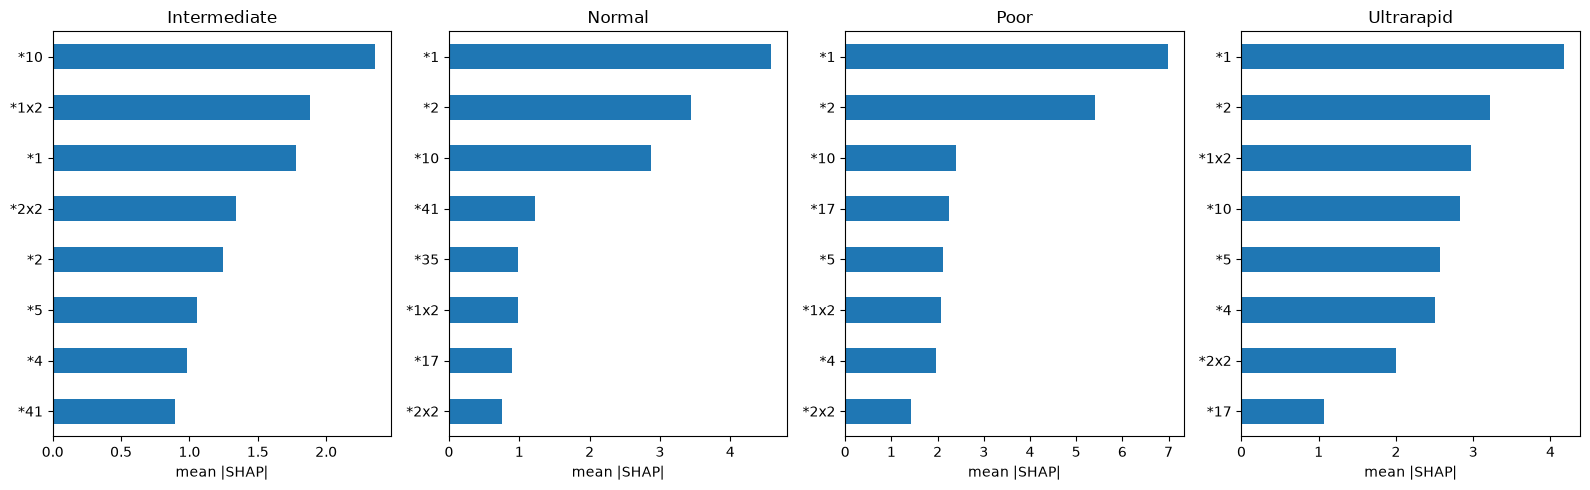

In [12]:
fn = pd.read_excel("data/CYP2D6_allele_functionality_reference.xlsx",
                   sheet_name="Allele Function", header=1).iloc[:, [0, 1]]
fn.columns = ["allele", "activity"]
fn["allele"] = fn["allele"].astype(str).str.strip()
act_map = dict(zip(fn["allele"], pd.to_numeric(fn["activity"], errors="coerce")))

short = {"CYP2D6 Poor Metabolizer": "Poor", "CYP2D6 Intermediate Metabolizer": "Intermediate",
         "CYP2D6 Normal Metabolizer": "Normal", "CYP2D6 Ultrarapid Metabolizer": "Ultrarapid"}

fig, axes = plt.subplots(1, 4, figsize=(16, 5))
for k, cls in enumerate(lr.classes_):
    m = pd.Series(np.abs(vals[:, :, k]).mean(axis=0), index=X.columns).sort_values(ascending=False).head(8)
    print(short[cls], "- top alleles (mean |SHAP|, CPIC activity):")
    print(pd.DataFrame({"mean_abs_shap": m.round(3), "activity": [act_map[a] for a in m.index]}))
    print()
    m.sort_values().plot.barh(ax=axes[k])
    axes[k].set_title(short[cls])
    axes[k].set_xlabel("mean |SHAP|")
plt.tight_layout()
plt.savefig("cyp2d6_shap_top_alleles.png", dpi=300)
plt.show()

In [13]:
top = ["*1", "*2", "*10", "*4", "*5", "*41", "*1x2", "*17"]
c = pd.DataFrame(lr.coef_, index=[short[k] for k in lr.classes_], columns=X.columns)[top].round(2)
c.loc["CPIC activity"] = [act_map[a] for a in top]
print(c.T)

      Intermediate  Normal   Poor  Ultrarapid  CPIC activity
*1           -2.91    7.51 -11.44        6.84           1.00
*2           -2.73    7.56 -11.88        7.05           1.00
*10           5.69    6.93  -5.80       -6.82           0.25
*4            5.99   -2.68  11.92      -15.22           0.00
*5            6.09   -3.44  12.20      -14.84           0.00
*41           4.34    5.98  -6.70       -3.62           0.25
*1x2        -12.74    6.62 -13.95       20.08           2.00
*17           0.84    2.68  -6.76        3.23           0.50
